## Notebook for calculating hourly growth rates from TSD results
Processing order:
1. Run par_normalization notebook to shift time of days
2. Run satellite_par R notebook to generate PAR
3. Run this notebook to calculate hourly growth data
4. Run new_PI curves notebook to fit PI parameters

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# suppress warnings
import warnings
warnings.simplefilter('ignore')

### Set time resolution

In [68]:
import re 

# define time resolution
timeres = '30min'
## calculate period based on 1 day
number = int(re.sub(r'\D', '', timeres)) # \D matches any non-digit character
# check if time resolution is in minutes
min_flag = 'min' in timeres
if min_flag:
    mins = int(number)
    # calculate hour fraction
    period = int((60 / mins) * 24)
    path = f'../data/{timeres}_sfl.csv'
    # calculate period (how many hours in a day)
else: # otherwise, periodicty is hourly
    period = int((24 / number))
    path = '../data/hourly_sfl.csv'

# calculate 1 hour offset from period
hour_offset = int(period / 24)
pops = ['prochloro', 'synecho', 'picoeuk']

### Load data

In [69]:
# Read in TSD and rates data based on time resolution
tsd_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/all_seaflow_tsd_mixed_v1_all_{timeres}.pickle'
rates_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/final_rates_v1_all_{timeres}.pickle'

all_tsd = pd.read_pickle(tsd_path)
final_rates = pd.read_pickle(rates_path)
# only get good tsd dimensions
good_tsd = final_rates[['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']].merge(all_tsd, how = 'left')

#### get all cruise data
aloha_df = final_rates[['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']].copy()
all_aloha = aloha_df.merge(all_tsd, how = 'left')

# read in smoothed PAR data
hot_cruise_smooth_all = pd.read_pickle(f'../data/smoothed_par_data/hot_cruise_smooth_{timeres}.pickle')
hot_cruise_smooth = hot_cruise_smooth_all.loc[hot_cruise_smooth_all['qc_flag'] == 0]

# astronomically derived PAR (piCurve() library)
sat_par_smooth = pd.read_csv(f'../data/smoothed_par_data/sat_par_data.csv').drop(columns = 'X')
# clean up unused cols
sat_par_smooth = sat_par_smooth.loc[(sat_par_smooth['coords_valid']== True) &
                   (sat_par_smooth['calculation_status'] == 'ok')]
sat_par_smooth.drop(columns = [
    'lat',
    'lon',
    'coord_status',
    'coords_valid',
    'tz_local',
    'date_local',
    'time_local',
    'sza',
    'calculation_status',
], inplace = True)
sat_par_smooth.rename(columns = {
    'lat_clean': 'lat',
    'lon_clean': 'lon'
}, inplace = True)
sat_par_smooth['time'] = pd.DatetimeIndex(sat_par_smooth['time']).tz_localize('UTC')

### Plot time series of diel component

In [70]:
# loop through each cruise and print diel times
pops = ['prochloro', 'synecho', 'picoeuk']
colors = ['tab:blue', 'tab:orange', 'tab:green']
# test_cruises = ['KM1513']

sns.set_style("white")
# loop thru each cruise around station aloha
for cruise in all_aloha['cruise'].unique():
    cruise_df = all_aloha.loc[(all_aloha['cruise'] == cruise)]
    for pop, c in zip(pops, colors):
        # grab tsd dimensions used to calculate productivity rates
        dims = cruise_df.loc[((cruise_df['pop']==pop))][['cruise', 'cruise_day', 'pop', 'model']]
        # print to make sure sunrise/sunset times are matching
        diel_df=dims.merge(all_tsd, how = 'left')
        if diel_df.empty:
            continue
        diel_df.sort_values(by='time', inplace=True)
        # plot diel cycle over time
        fig,axs=plt.subplots(figsize=(10,6))
        x=diel_df['hour']
        y=diel_df['data_with_missing']
        # plot
        axs.plot(x, y,marker='.',label='Diel Component', c=c)
        # show day/night
        twinax=axs.twinx()
        twinax.fill_between(diel_df['hour'], 0, 1, where=diel_df['time_of_day']=='night',color='gray',
                            alpha=0.3, transform=axs.get_xaxis_transform())
        # hide y ticks
        twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                            right=False, labelright=False, bottom=False, labelbottom=False)

        axs.set_xlabel('Hours since cruise start')
        axs.set_ylabel('Qc (pg C cell-1)')
        cruise=pd.unique(diel_df['cruise'])[0]
        axs.set_title(f'{cruise}: {pop}')
        plt.close()

### Smooth and plot diel component
- Smooth diel component time series with:
    - 2nd order polynomial function
    - Lowess regression
- Diel component and PAR over time

In [80]:
# ## original smoothing with lowess regression

# import statsmodels.api as sm

# # save dfs with regression results
# smoothed_dfs = []

# for cruise in hot_cruise_smooth['cruise'].unique():
#     cruise_df = hot_cruise_smooth.loc[(hot_cruise_smooth['cruise']==cruise)]
#     for pop, c in zip(pops, colors):
#         # cruise_df = hot_cruise.loc[(hot_cruise['pop']==pop)]
#         pop_df = cruise_df.loc[(cruise_df['pop']==pop)]
#         # loop through each day and fit a line of best fit
#         for day in pop_df['cruise_day'].unique():
#             data = pop_df.loc[(pop_df['cruise_day'] == day) & (pop_df['time_of_day'] != 'night')]
#             if data.empty:
#                 continue
#             # reset x to represent hours after sunset
#             reset_x = data['day_hour']
#             y = data['log_diel']
#             # calculate best line of fit (2nd order poly)
#             #find line of best fit
#             order = 2
#             z = np.polyfit(reset_x, y, order)
#             fit = np.poly1d(z)
#             # #add points to plot
#             fig, axs = plt.subplots()
#             axs.scatter(reset_x, y, color=c)
#             # plot first regression
#             axs.plot(reset_x, fit(reset_x), color='steelblue', linestyle='--', linewidth=2, label = '2nd order polynomial')

#             # compute LOWESS smoothing
#             frac = 0.43
#             smoothed = sm.nonparametric.lowess(endog=y, exog=reset_x, frac=frac)
#             # add lowess results to plot
#             data['lowess_diel'] = smoothed[:, 1]
#             smoothed_dfs.append(data)
#             # add LOWESS fit to plot
#             axs.plot(smoothed[:, 0], smoothed[:, 1], color='red', linestyle='--', linewidth=2, label = 'Lowess Regression')
#             # set x axis bounds
#             axs.set_title(f'{pop}')
#             axs.set_xlim((-0.5, 14.5))
#             axs.legend()

In [71]:
#### using with both savgol and lowess filters

from scipy.signal import savgol_filter
import statsmodels.api as sm


# Save daily DataFrames containing Savitzky–Golay results.
smoothed_dfs = []
## calculate window size
# # 4.5ish hour smoothing based on time res (ex: 9 window size = 4.5 hours at 30-minute sampling)
window_length = int(4.5 * hour_offset)
# make sure window size is odd, increase by 1 if not odd
if window_length % 2 == 0: 
    window_length += 1
polyorder = 2
## do a test cruise
diel_cruise = hot_cruise_smooth.loc[hot_cruise_smooth['cruise'] == 'KM1513']


for cruise in hot_cruise_smooth["cruise"].unique():

    cruise_df = hot_cruise_smooth.loc[
        hot_cruise_smooth["cruise"] == cruise
    ].copy()

    for pop, c in zip(pops, colors):

        pop_df = cruise_df.loc[
            cruise_df["pop"] == pop
        ].copy()

        for day in pop_df["cruise_day"].unique():

            # Keep only non-nighttime observations for this cruise/pop/day.
            data = pop_df.loc[
                (pop_df["cruise_day"] == day)
                & (pop_df["time_of_day"].astype(str).str.lower() != "night")
            ].reset_index(drop=True).copy()

            # Remove missing values and ensure chronological ordering.
            data = (
                data.dropna(subset=["day_hour", "log_diel"])
                .sort_values("day_hour")
                .copy()
            )

            if data.empty:
                continue

            reset_x = data["day_hour"].to_numpy(dtype=float)
            y = data["log_diel"].to_numpy(dtype=float)

            # Ensure an odd window that does not exceed the number of points.
            this_window = min(window_length, len(y))

            if this_window % 2 == 0:
                this_window -= 1

            # Apply Savitzky–Golay only when enough points are available.
            if this_window > polyorder:
                sg_smoothed = savgol_filter(
                    y,
                    window_length=this_window,
                    polyorder=polyorder,
                    mode="interp",
                )
            else:
                sg_smoothed = y.copy()

            data["savgol_diel"] = sg_smoothed
            
            # also fit lowess curve  
            frac = 0.43
            smoothed = sm.nonparametric.lowess(endog=y, exog=reset_x, frac=frac)
            # add lowess results to plot
            data['lowess_diel'] = smoothed[:, 1]
    
            smoothed_dfs.append(data)

            # Optional: retain your quadratic fit for comparison.
            if len(y) >= 3:
                z = np.polyfit(reset_x, y, 2)
                quadratic_fit = np.poly1d(z)

            # Plot the raw observations and Savitzky–Golay curve.
            fig, ax = plt.subplots()
            # plot data
            ax.scatter(
                reset_x,
                y,
                color=c,
                label="Observed log_diel",
            )
            # plot savgol fit
            ax.plot(
                reset_x,
                sg_smoothed,
                color="red",
                linestyle="--",
                linewidth=2,
                label=f"Savitzky–Golay (window={this_window}, order={polyorder})",
            )

            # add LOWESS fit to plot
            ax.plot(smoothed[:, 0], 
                    smoothed[:, 1], 
                    color='magenta', 
                    linestyle='--', 
                    linewidth=2, 
                    label = 'Lowess Regression')

            # plot quadratic-fit line.
            if len(y) >= 3:
                ax.plot(
                    reset_x,
                    quadratic_fit(reset_x),
                    color="green",
                    linestyle="--",
                    linewidth=2,
                    label="Quadratic fit",
                )

            ax.set_title(f"Cruise {cruise} | Pop {pop} | Cruise day {day}")
            ax.set_xlim((-0.5, 14.5))
            ax.set_xlabel("Day hour")
            ax.set_ylabel("log_diel")
            ax.legend()
            # plt.show()
            plt.close()
# append diel data with smoothed regression from lowess and savgol filters
smooth_cruise = pd.concat(smoothed_dfs)

### Compare diel component over PAR

In [17]:
# make custom scatter plot
# Custom plotting function to reset x-axis
## helper function: data= dataframe, y = column to plot
def scatter_with_reset_x(data, **kwargs):
    # use daily hour as x 
    reset_x = data['day_hour']
    # plot observations
    plt.scatter(reset_x, data["savgol_diel"], **kwargs)
    # add calculated regression line
    slope = np.mean(data['daily_growth'])
    # set sunrise as y_int
    y_int = data.loc[data['time_of_day'] == 'sunrise', 'savgol_diel'].values
    # if there is no sunrise (incomplete day)
    if len(y_int) == 0:
        # set y int as first value
        y_int = data['savgol_diel'].values[0]
    else:
        y_int = y_int[0]
    # plot regression line
    plt.plot(reset_x, slope*reset_x + y_int, color='red', linestyle = '--')
    # add aesthetics
    plt.xlabel("Hours after Dawn")
    plt.ylabel("Smoothed Diel")
    # plot par on secondary axis
    twinax = plt.twinx()
    twinax.scatter(reset_x, data["par_smooth"], c = 'goldenrod', alpha = 0.75, label = 'Smoothed Observations')
    twinax.scatter(reset_x, data["sat_par"], c = 'r', alpha = 0.75, label = 'Model')
    twinax.legend('PAR Type')
    
for cruise in smooth_cruise['cruise'].unique():
    cruise_df = smooth_cruise.loc[smooth_cruise['cruise'] == cruise]
    # make a loop to plot each cruise
    for pop, c in zip(pops, colors):
        # get subdf for each cruise
        pop_df = cruise_df.loc[(cruise_df['pop']==pop) & (cruise_df['time_of_day']!='night')]
        if pop_df.empty:
            continue
        # plot
        g = sns.FacetGrid(pop_df, col="cruise_day", col_wrap = 4)
        g.map_dataframe(scatter_with_reset_x)
        # remove subplot titles
        g.set_titles("")
        # set cruise title
        g.figure.suptitle(f'{cruise}: {pop}')
        # plt.show()
        plt.close()

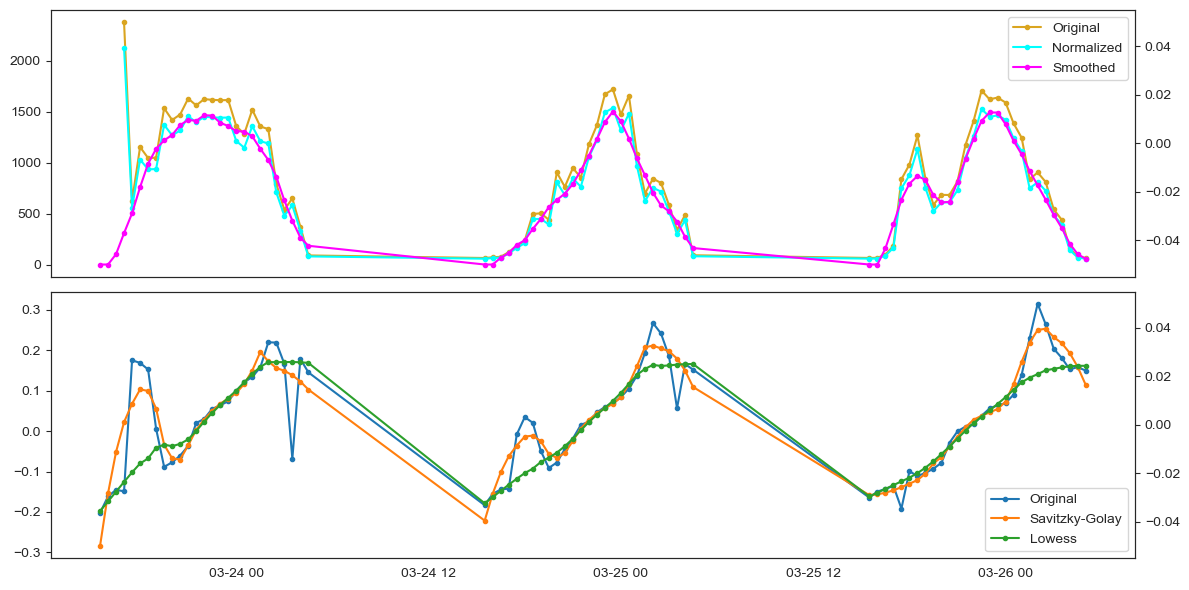

In [76]:
## testing
diel_cruise = smooth_cruise.loc[smooth_cruise['cruise'] == 'KM2103']
pro_test = diel_cruise.loc[diel_cruise['pop'] == 'prochloro'].reset_index(drop = True).sort_values(by = 'time')
fig, axs = plt.subplots(figsize = (12, 6), nrows = 2, sharex = True)

axs[0].plot(pro_test['time'], pro_test['par'], marker = '.', c = 'goldenrod', label = 'Original')
axs[0].plot(pro_test['time'], pro_test['norm_par'], marker = '.', c = 'cyan', label = 'Normalized')
axs[0].plot(pro_test['time'], pro_test['norm_par_smooth'], marker = '.', c = 'magenta', label = 'Smoothed')
# plot day night cycle
twinax = axs[0].twinx()
twinax.fill_between(pro_test['time'], 0, 1, where=pro_test['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform = axs[0].get_xaxis_transform())

axs[1].plot(pro_test['time'], pro_test['log_diel'], marker = '.', label = 'Original')
axs[1].plot(pro_test['time'], pro_test['savgol_diel'], marker = '.', label = 'Savitzky-Golay')
axs[1].plot(pro_test['time'], pro_test['lowess_diel'], marker = '.', label = 'Lowess')
axs[0].legend()
axs[1].legend()
plt.tight_layout()
twinax = axs[1].twinx()
twinax.fill_between(pro_test['time'], 0, 1, where=pro_test['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform = axs[1].get_xaxis_transform())
# plt.close()

### Plot variability of diel component per hour
- Hourly box plots of diel component for each cruise

In [72]:
from matplotlib.backends.backend_pdf import PdfPages

for pop, c in zip(pops, colors):
        # subset bya
        # pop
        pop_df = smooth_cruise.loc[smooth_cruise['pop'] == pop]
        # save in a pdf
        with PdfPages(f'../figures/{pop}_boxplots_{timeres}.pdf') as pdf:
                # loop through each cruise to make summarized figure of Qc diel 
                for cruise in hot_cruise_smooth['cruise'].unique():
                        test_cruise = pop_df.loc[(pop_df['cruise'] == cruise) & (pop_df['time_of_day'] != 'night')]
                        if test_cruise.empty:
                                continue
                        # extract date for grouping
                        test_cruise['date'] = pd.to_datetime(test_cruise['time']).dt.date
                        # create day_hour 0–23 within each day, ordered by time
                        test_cruise['day_hour'] = test_cruise.groupby('cruise_day').cumcount()
                        # create plot object
                        fig, axs = plt.subplots()
                        # box plot
                        sns.boxplot(test_cruise, 
                                x = 'day_hour', y = 'savgol_diel', showfliers = False, 
                                boxprops={'facecolor': c, 'alpha': 0.75}, ax = axs)
                        sunset_hour = np.mean(test_cruise.loc[test_cruise['time_of_day'] == 'sunset', 'day_hour'])#.round()
                        plt.axvline(x = sunset_hour, c = 'r', label = 'sunset')

                        # figure with lowess
                        sns.regplot(test_cruise.loc[test_cruise['time_of_day'] != 'night'], 
                                x = 'day_hour', y = 'savgol_diel', lowess= True, ax = axs, 
                                scatter_kws={"color": c}, line_kws={'color': c})
                        plt.legend()
                        plt.xlabel('Hours after Dawn')
                        plt.ylabel('Savgol Smoothed Diel (pg C / cell)')
                        plt.title(f'{cruise}: {pop}')
                        pdf.savefig(fig)
                        plt.close()

### Incoprorate MLD from 1 cruise (KM1513)

In [34]:
mld_path = '~/Desktop/UW/projects/pe_curves/data/km1513_mld_clean.txt'
mld_df = pd.read_csv(
    mld_path,
    delim_whitespace=True,   # treat any whitespace as the separator
    comment="#"              # optional, in case there are comment lines
)
# convert julian day to actual days
## Year corresponding to your julian days
year = 2015
# Convert julday (e.g. 206.84) to datetime in UTC
base = pd.Timestamp(f"{year}-01-01T00:00:00Z")
mld_df["datetime_utc"] = base + pd.to_timedelta(mld_df["julday"] - 1, unit="D")
# round to the nearest hour
mld_df["time"] = mld_df["datetime_utc"].dt.round(timeres)
# calculate the mean MLD across the 3 methods
mld_df['mean_MLD'] = (mld_df['MLD1'] + mld_df['MLD2'] + mld_df['MLD3']) / 3
daily_mld = mld_df[['time', 'mean_MLD']].merge(hot_cruise_smooth[['cruise', 
                                                   'time', 
                                                   'cruise_day']]).groupby(['cruise', 
                                                                            'cruise_day']).mean().reset_index()

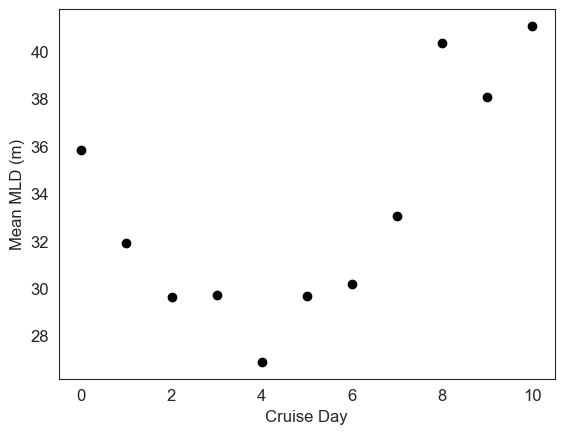

In [35]:
# plot mixed layer depth over time
fig, axs = plt.subplots()
axs.scatter(daily_mld['cruise_day'], daily_mld['mean_MLD'], marker = 'o', c = 'k')
axs.set_xlabel('Cruise Day', fontsize = 12)
axs.set_ylabel('Mean MLD (m)', fontsize = 12)
axs.tick_params(axis = 'both', labelsize = 12)
# plt.close()

In [37]:
## clean up dataframe and add MLD/PAR data
# create column for seasons
smooth_cruise['season'] = pd.to_datetime(smooth_cruise['time']).dt.month % 12 // 3 + 1
# map to seasons
seasons = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}
smooth_cruise['season'] = smooth_cruise['season'].map(seasons)
# sort df by season
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
smooth_cruise['season'] = pd.Categorical(smooth_cruise['season'], categories = season_order, ordered = True)
# merge with MLD data
smooth_mld = smooth_cruise.merge(daily_mld[['cruise', 'cruise_day', 'mean_MLD']], how = 'left')
# filter out "bad" cruises that have suspicious PAR or no par (~smooth_mld['cruise'].isin(bad['cruise'])) &
smooth_mld = smooth_mld.loc[(smooth_mld['norm_par_smooth'].notnull())]

### Growth-Irradiance Curves
#### Calculate hourly growth from lowess smoothed diel component
- Calculate for each day for each population
    
#### Adjustments to make
1) Make sure each day starts at par = 0 or rounded to 0, this may require some shifting with sunrise start
2) Recalculate growth rate starting from where par = 0 on each day    

In [38]:
# #display(hot_cruise_smooth.head(50)[['cruise', 'pop', 'time', 'cruise_day', 'par_smooth', 'time_of_day']])
# hot_cruise_smooth.loc[(hot_cruise_smooth['cruise'] == 'KM1513') & 
#                (hot_cruise_smooth['pop'] == 'prochloro')].head(50)[['cruise', 'pop', 'time', 'cruise_day', 'par_smooth', 'time_of_day']]

In [45]:
## calcualte growth from both savgol and lowess smoothed diel compoennts
from scipy import stats 

# inputs: df = dataframe to calculate growth rate from diel component, diel_col = str to identify which 
# column to calculate growth rate from 
# output: dataframe with growth parameters
def create_growth_df(df, diel_col):
    # save data in a dict
    growth_vals = {'cruise_day': [],
                   'pop': [],
                   'time': [],
                    'hour': [],
                    'slope': [],
                    'yint': [],
                    'mld': [],
                    'norm_par_smooth': [],
                    'int_par': []}

    test_pop = df.sort_values(by='time').reset_index(drop=True)
    pop = df['pop'].unique()[0]
    # loop through each day
    for day in test_pop['cruise_day'].unique():
        day_df = test_pop.loc[test_pop['cruise_day'] == day].reset_index(drop = True)
        # define sunset hour to end the day with
        sunset_hour = day_df.loc[day_df['time_of_day'] == 'sunset', 'day_hour']
        if sunset_hour.empty:
            continue
        else:
            sunset_hour = sunset_hour.values[0]
        # add a zeroed out hour 1
        growth_vals['cruise_day'].append(day)
        growth_vals['pop'].append(pop)
        growth_vals['time'].append(day_df['time'].values[0] - np.timedelta64(1, 'h'))
        growth_vals['hour'].append(0)
        growth_vals['slope'].append(0)
        growth_vals['yint'].append(0)
        growth_vals['mld'].append(np.mean(day_df['mean_MLD']))
        # get PAR and integrated PAR
        growth_vals['norm_par_smooth'].append(0)
        growth_vals['int_par'].append(0)
        # increase day hour by 1 for each day
        day_df['day_hour'] += 1
        # loop through each hour to calculate the hourly growth rate
        for hour in day_df['day_hour'].unique():
            # subset
            start_diel = day_df.loc[day_df['day_hour'] == hour, diel_col].values
            # set x
            hour_start = np.tile(hour, len(start_diel))
            # check if we are at the end of day
            if hour == sunset_hour:
                break
            else:
                # grab the next hour
                end_diel = day_df.loc[day_df['day_hour'] == hour + 1, diel_col].values
                # set y
                hour_end = np.tile(hour+1, len(end_diel))
                # calculate slope between start and end
                x = np.concat((hour_start, hour_end))
                y = np.concat((start_diel, end_diel))
                slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

                # Skip nonpositive or nonfinite slopes.
                if not np.isfinite(slope) or slope <= 0:
                    continue

                # save into dict
                growth_vals['cruise_day'].append(day)
                growth_vals['pop'].append(pop)
                # display(day_df.loc[day_df['day_hour'] == hour])
                growth_vals['time'].append(day_df.loc[day_df['day_hour'] == hour, 'time'].values[0])
                growth_vals['hour'].append(np.min(x))
                growth_vals['slope'].append(slope)
                growth_vals['yint'].append(intercept)
                growth_vals['mld'].append(np.mean(day_df['mean_MLD']))
                # get PAR and integrated PAR
                growth_vals['norm_par_smooth'].append(day_df.loc[day_df['day_hour'] == hour, 'norm_par_smooth'].values[0])
                growth_vals['int_par'].append(day_df.loc[day_df['day_hour'] == hour, 'int_par'].values[0])

    daily_pe = pd.DataFrame(growth_vals)

    # round par data
    bin = 50
    daily_pe['round_par'] = np.round(daily_pe['norm_par_smooth'] / bin) * bin
    return daily_pe

# helper function to apply mean mld to each day of facet plots
def add_mean_line(data, **kwargs):
    # Calculate a value specific to this facet's data
    mean_val = data['mld'].mean()
    # Get current axis
    ax = plt.gca()
    # create a twin axis
    twinax = ax.twinx()
    # Add the line to twinax
    twinax.axhline(mean_val, color='k', ls='--')
    twinax.set_ylabel('MLD')
    # set lims
    twinax.set_ylim(25, 50)
    # invert y-axis
    twinax.invert_yaxis()

For PDF generation to work, need to make sure OneDrive is not syncing! (learned this the hard way RIP)

In [49]:
from matplotlib.backends.backend_pdf import PdfPages

# loop and plot growth rate for each population
growth_dfs = []
# set diel col (lowess or savgol_diel)
filter_type = 'lowess'
diel_col = f'{filter_type}_diel'

# testing 
pops = ['prochloro', 'synecho', 'picoeuk']
for pop, c in zip(pops, colors):
    pop_df = smooth_mld.loc[smooth_mld['pop'] == pop]
    pdf_path = f'../figures/{pop}_growth_light_plots_all_{timeres}_{filter_type}.pdf'
    with PdfPages(pdf_path) as pdf: ## testing
        # split into seasons
        for season in season_order:
            season_df = pop_df.loc[pop_df['season'] == season]
            # split by cruise
            for cruise, cruise_df in season_df.groupby('cruise'):
                daily_pe = create_growth_df(cruise_df, diel_col)
                # remove all days where no par data
                daily_pe = daily_pe.loc[daily_pe['norm_par_smooth'].notnull()]
                # hopefully daily pe is also not empty but just in case
                if daily_pe.empty:
                    continue
                # add a column for cruise and season
                daily_pe['cruise'] = cruise
                daily_pe['season'] = season
                # calculate the first and second half of each day
                # compute daylight bounds per cruise_day 
                day_bounds = daily_pe.groupby('cruise_day')['hour'].agg(hour_max = 'max', first_hour = 'min').reset_index()
                # calculate the offset to add to hour 1
                day_bounds['halfway_offset'] = np.round(day_bounds['hour_max'] / 2)
                day_bounds['halfway_hour'] = day_bounds['halfway_offset'] + day_bounds['first_hour'] + 2
                # merge back onto daily_pe
                daily_pe = daily_pe.merge(
                    day_bounds[['cruise_day', 'halfway_hour']],
                    on='cruise_day',
                    how='left'
                )
                # classify each point by first vs second half of daylight period
                daily_pe['day_half'] = np.where(
                    daily_pe['hour'] < daily_pe['halfway_hour'],
                    'first',
                    'second'
                )
                # save
                growth_dfs.append(daily_pe)
                ## plot by day half
                g = sns.FacetGrid(daily_pe, col="cruise_day", hue = 'day_half', col_wrap = 4)
                g.map(sns.scatterplot, 'norm_par_smooth', 'slope')
                # remove subplot titles
                g.set_titles("")
                g.set(xlim = (-100, 3000))
                # set cruise title
                g.figure.suptitle(f'{cruise} ({season}): {pop}')
                g.set_axis_labels("Instantaneous PAR (µE m-2 s-1)", "Growth Rate (hour-1)")
                g.add_legend()
                # save into pdf
                pdf.savefig(g.figure)
                plt.close()

In [50]:
### save data
# exclude bad cruises
all_growth = pd.concat(growth_dfs)
clean_growth = all_growth.copy()#loc[~all_growth['cruise'].isin(bad['cruise'].values)]
# make negative growht rates 0
clean_growth.loc[clean_growth['slope'] < 0, 'slope'] = 0
## save growth rate data
clean_growth.to_csv(f'../data/smoothed_growth_data/clean_growth_{timeres}_{filter_type}.csv')
## save cruise data 
hot_cruise_smooth.to_csv(f'../data/smoothed_growth_data/all_smooth_diel_{timeres}_{filter_type}.csv')
## save smoothed mixed layer depth data
smooth_mld.to_csv(f'../data/smoothed_growth_data/all_days-only_mld_{timeres}_{filter_type}.csv')

In [66]:
test = hot_cruise_smooth_all.loc[(hot_cruise_smooth_all['cruise'] == 'KM1513') & 
               (hot_cruise_smooth_all['pop'] == 'prochloro')]

test.loc[test['cruise_day'] == 1]

,time,cruise,pop,model,lat,lon,diel,log_diel,trend,resid,...,sg_window_used,par_smooth_before_zero,solar_night,high_par_during_solar_night,norm_par_smooth,par_forced_zero,int_par,daily_growth,qc_merge,qc_flag
27257,2015-07-25 15:00:00+00:00,KM1513,prochloro,Rolling,23.376630,-157.222840,0.939173,-0.062755,0.026116,0.931509,...,9.0,-17.683126,True,False,0.000000,True,0.000000e+00,0.014223,both,0
27258,2015-07-25 15:00:00+00:00,KM1513,prochloro,STL,23.376630,-157.222840,0.863323,-0.146966,0.026625,0.992099,...,9.0,-17.683126,True,False,0.000000,True,0.000000e+00,NaN,left_only,1
27263,2015-07-25 15:30:00+00:00,KM1513,prochloro,Rolling,23.463470,-157.179500,0.847699,-0.165229,0.026084,1.021957,...,9.0,-21.749914,True,False,0.000000,True,0.000000e+00,0.014223,both,0
27264,2015-07-25 15:30:00+00:00,KM1513,prochloro,STL,23.463470,-157.179500,0.852185,-0.159952,0.026582,0.995896,...,9.0,-21.749914,True,False,0.000000,True,0.000000e+00,NaN,left_only,1
27365,2015-07-26 00:00:00+00:00,KM1513,prochloro,Rolling,24.203350,-156.795150,1.003923,0.003915,0.025566,0.962940,...,9.0,2423.940973,False,False,2423.940973,False,8.726188e+06,0.014223,both,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27636,2015-07-26 22:30:00+00:00,KM1513,prochloro,STL,24.376070,-156.776560,1.005591,0.005575,0.025363,1.003263,...,9.0,2528.571216,False,False,2528.571216,False,1.517193e+08,NaN,left_only,1
27641,2015-07-26 23:00:00+00:00,KM1513,prochloro,Rolling,24.387560,-156.766600,1.038301,0.037586,0.025867,0.952414,...,9.0,2512.796547,False,False,2512.796547,False,1.607654e+08,0.014223,both,0
27642,2015-07-26 23:00:00+00:00,KM1513,prochloro,STL,24.387560,-156.766600,1.020732,0.020520,0.025360,0.987946,...,9.0,2512.796547,False,False,2512.796547,False,1.607654e+08,NaN,left_only,1
27647,2015-07-26 23:30:00+00:00,KM1513,prochloro,Rolling,24.387822,-156.766489,1.035398,0.034786,0.025807,0.961039,...,9.0,2409.114788,False,False,2409.114788,False,1.694382e+08,0.014223,both,0


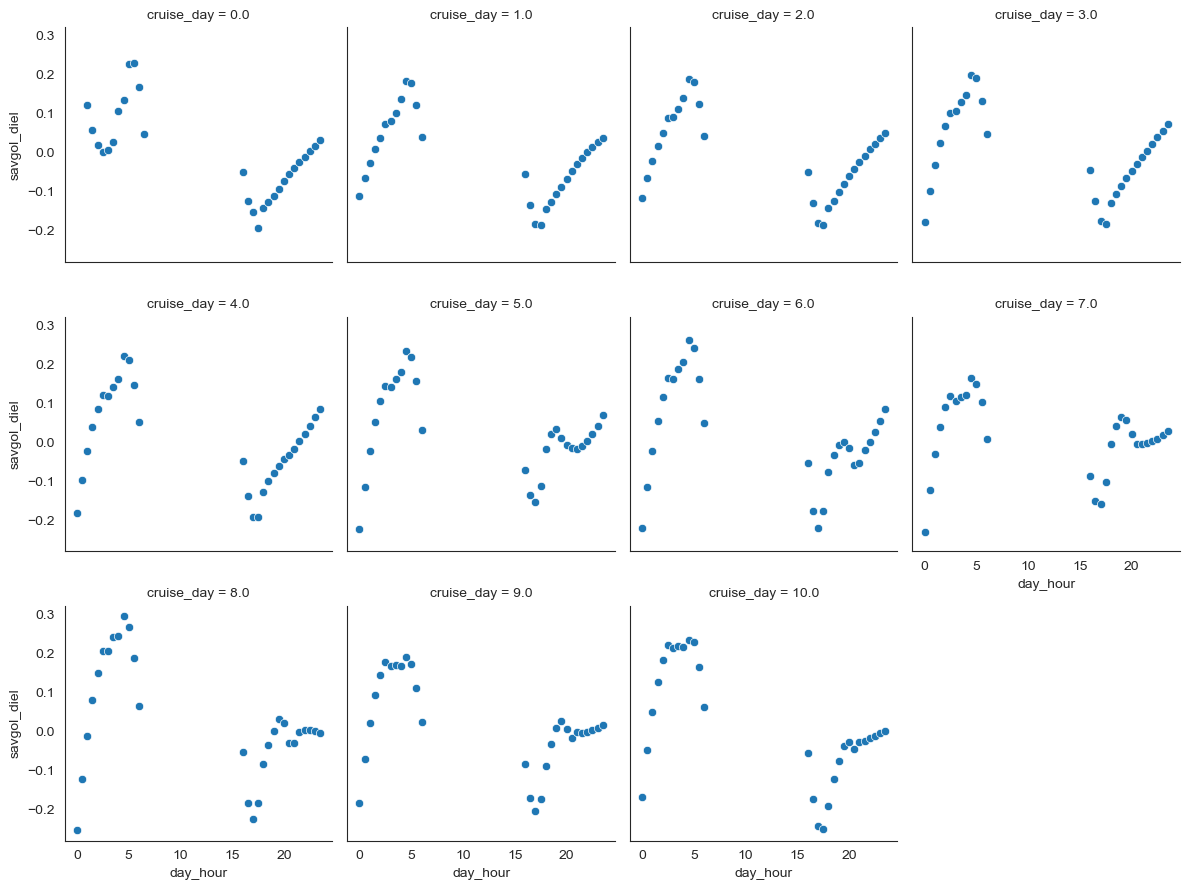

In [ ]:
# plot diel and PAR datas
test = smooth_cruise.loc[(smooth_cruise['cruise'] == 'KM1513') & 
               (smooth_cruise['pop'] == 'prochloro')]
# plot diel and par for test cruise
g = sns.FacetGrid(test, col = 'cruise_day', col_wrap = 4)
g.map_dataframe(sns.scatterplot, x = 'day_hour', y = 'savgol_diel')

####### cruise day is getting messed up somehow– WHERE is this happening??? ########

# ### plot growth rates
# test = all_growth.loc[(all_growth['cruise'] == 'KM1513') & 
#                (all_growth['pop'] == 'prochloro')]
# # plot diel and par for test cruise
# g = sns.FacetGrid(test, col = 'cruise_day', col_wrap = 4)
# g.map_dataframe(sns.scatterplot, x = 'norm_par_smooth', y = 'slope')

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages

# loop and plot growth rate for each population
growth_dfs = []

# testing 
pops = ['prochloro', 'synecho', 'picoeuk']
for pop, c in zip(pops, colors):
    pop_df = smooth_mld.loc[smooth_mld['pop'] == pop]
    with PdfPages(f'../figures/{pop}_growth_intlight_plots_all_{timeres}_{filter_type}.pdf') as pdf:
        # split into seasons
        for season in season_order:
            season_df = pop_df.loc[pop_df['season'] == season]
            # split by cruise
            for cruise, cruise_df in season_df.groupby('cruise'):
                daily_pe = create_growth_df(cruise_df)
                # remove all days where no par data
                daily_pe = daily_pe.loc[daily_pe['int_par'].notnull()]
                # hopefully daily pe is also not empty but just in case
                if daily_pe.empty:
                    continue
                # add a column for cruise and season
                daily_pe['cruise'] = cruise
                daily_pe['season'] = season
                # calculate the first and second half of each day
                # compute daylight bounds per cruise_day 
                day_bounds = daily_pe.groupby('cruise_day')['hour'].agg(hour_max = 'max', first_hour = 'min').reset_index()
                # calculate the offset to add to hour 1
                day_bounds['halfway_offset'] = np.round(day_bounds['hour_max'] / 2)
                day_bounds['halfway_hour'] = day_bounds['halfway_offset'] + day_bounds['first_hour'] + 2
                # merge back onto daily_pe
                daily_pe = daily_pe.merge(
                    day_bounds[['cruise_day', 'halfway_hour']],
                    on='cruise_day',
                    how='left'
                )
                # classify each point by first vs second half of daylight period
                daily_pe['day_half'] = np.where(
                    daily_pe['hour'] < daily_pe['halfway_hour'],
                    'first',
                    'second'
                )
                # save
                growth_dfs.append(daily_pe)
                ## plot by day half
                g = sns.FacetGrid(daily_pe, col="cruise_day", hue = 'day_half', col_wrap = 4)
                g.map(sns.scatterplot, 'int_par', 'slope')
                # remove subplot titles
                g.set_titles("")
                # g.set(xlim = (-100, 3000))
                # set cruise title
                g.figure.suptitle(f'{cruise} ({season}): {pop}')
                g.set_axis_labels("Integrated PAR (µE m-2)", "Growth Rate (hour-1)")
                g.add_legend()
                # save into pdf
                pdf.savefig(g.figure)
                plt.close()

In [103]:
# make dataframe for mohammad
m_df = clean_growth.copy()
cols = ['cruise', 'pop', 'cruise_day', 'time', 'slope', 'par_smooth']
m_sub = m_df[cols].loc[m_df['pop'] == 'prochloro']
m_sub.rename(columns = {'slope': 'hourly_growth', 
                        'par_smooth': 'PAR'}, inplace = True)
m_sub.to_csv('../data/pro_hourly_growth_par.csv')

In [ ]:
### testing
# all_growth.loc[(all_growth['cruise'] == 'KM1513') & 
#                (all_growth['pop'] == 'prochloro')].head(20)